<a href="https://colab.research.google.com/github/asnapareeth004-hue/encoder_decoder/blob/main/Transformer_with_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Transformer with LSTM**

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)
torch.manual_seed(0)
np.random.seed(0)

Using: cpu


In [ ]:
# ---------------- Data ----------------
t = np.arange(0, 3000)
signal = np.sin(0.05 * t) + 0.5 * np.sin(0.13 * t) + 0.1 * np.random.randn(len(t))
signal = ((signal - signal.mean()) / signal.std()).astype(np.float32)

WINDOW = 50


def make_windows(x, window):
    X = np.stack([x[i : i + window] for i in range(len(x) - window)])
    y = x[window:]
    return torch.tensor(X).unsqueeze(-1), torch.tensor(y).unsqueeze(-1)  # (N, W, 1), (N, 1)


X, y = make_windows(signal, WINDOW)
split = int(0.8 * len(X))
train_dl = DataLoader(TensorDataset(X[:split], y[:split]), batch_size=64, shuffle=True)
X_test, y_test = X[split:].to(device), y[split:].to(device)

In [ ]:
# ---------------- Model ----------------
class LSTMTransformer(nn.Module):
    def __init__(self, in_dim=1, d_model=64, n_heads=4, lstm_layers=1,
                 tf_layers=2, d_ff=128, dropout=0.1, out_dim=1):
        super().__init__()
        self.proj = nn.Linear(in_dim, d_model)
        self.lstm = nn.LSTM(d_model, d_model, num_layers=lstm_layers, batch_first=True)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads, dim_feedforward=d_ff,
            dropout=dropout, batch_first=True,
        )
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers=tf_layers)
        self.head = nn.Sequential(nn.LayerNorm(d_model), nn.Linear(d_model, out_dim))

    def forward(self, x):
        x = self.proj(x)
        x, _ = self.lstm(x)
        x = self.transformer(x)
        return self.head(x[:, -1])


model = LSTMTransformer().to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")


Parameters: 100,545


In [ ]:
# ---------------- Train ----------------
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

for epoch in range(1, 11):
    model.train()
    total = 0.0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        loss = loss_fn(model(xb), yb)
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        total += loss.item() * len(xb)

    model.eval()
    with torch.no_grad():
        test_loss = loss_fn(model(X_test), y_test).item()
    print(f"epoch {epoch:2d} | train MSE {total / split:.4f} | test MSE {test_loss:.4f}")


epoch  1 | train MSE 0.0234 | test MSE 0.0194
epoch  2 | train MSE 0.0209 | test MSE 0.0222
epoch  3 | train MSE 0.0211 | test MSE 0.0202
epoch  4 | train MSE 0.0210 | test MSE 0.0187
epoch  5 | train MSE 0.0201 | test MSE 0.0203
epoch  6 | train MSE 0.0208 | test MSE 0.0180
epoch  7 | train MSE 0.0218 | test MSE 0.0189
epoch  8 | train MSE 0.0215 | test MSE 0.0185
epoch  9 | train MSE 0.0205 | test MSE 0.0182
epoch 10 | train MSE 0.0205 | test MSE 0.0193


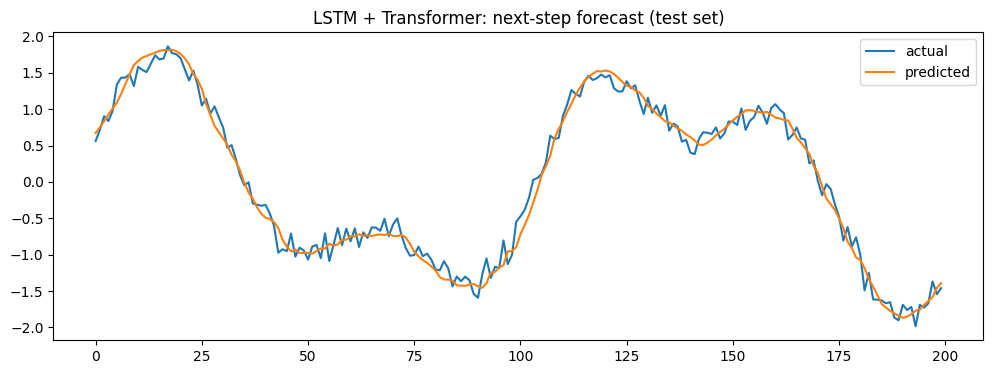

In [ ]:
# ---------------- Plot predictions ----------------
model.eval()
with torch.no_grad():
    preds = model(X_test).cpu().numpy().ravel()

plt.figure(figsize=(12, 4))
plt.plot(y_test.cpu().numpy().ravel()[:200], label="actual")
plt.plot(preds[:200], label="predicted")
plt.title("LSTM + Transformer: next-step forecast (test set)")
plt.legend()
plt.show()